# Сравнение top-10 рекомендаций

Автор: **Лебедев Александр Владимирович**.

Данные: dunnhumby, The Complete Journey (CSV release 2014).

Задача — предложить домохозяйству десять товаров, которых ещё не было в его истории покупок. Сравниваю ItemKNN, iALS, EASE, FM и iALS с другим целевым сигналом.

Для запуска нужен Python 3.11 или 3.12. Из корня репозитория:

```bash
python -m venv .venv
source .venv/bin/activate
pip install -r hw1/requirements.txt
cd hw1
jupyter lab experiments.ipynb
```

После этого выполнить **Restart Kernel and Run All Cells**. При первом запуске код попробует скачать CSV в `~/.cache/recsys_hw1`. Доступность загрузки зависит от сети и Kaggle; данные в репозиторий не входят.

Если загрузка недоступна, скачать CSV-версию 2014 года из [зеркала, версия 1](https://www.kaggle.com/datasets/frtgnn/dunnhumby-the-complete-journey/versions/1), распаковать `transaction_data.csv` и `product.csv` в одну папку. До запуска Jupyter указать путь к ней:

```bash
export DUNNHUMBY_DIR="/полный/путь/к/папке"
jupyter lab experiments.ipynb
```

Проверка SHA-256 не даст незаметно использовать другую версию. При ошибке загрузки код останавливается с инструкцией для ручного способа.

In [1]:
from pathlib import Path
from time import perf_counter
import gc
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

from data import (load_data, prepare_data, history_matrices, make_item_features,
                  TRAIN_DAY, VALID_DAY, LAST_DAY, MAX_ITEMS)
from evaluation import evaluate, evaluation_context, Popularity, PRIMARY_METRIC, top_items
from models import ItemKNN, IALS, EASE, FM, CustomIALS
from checks import check_implementations

SEED = 42
K = 10
np.random.seed(SEED)
blas_limit = threadpool_limits(limits=1)
pd.set_option('display.max_colwidth', 140)
plt.rcParams.update({'figure.figsize': (10, 3.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
print('Python:', platform.python_version())
print('NumPy:', np.__version__, 'pandas:', pd.__version__)
print('Основная метрика:', PRIMARY_METRIC)

Python: 3.12.14
NumPy: 2.3.5 pandas: 2.2.3
Основная метрика: NDCG@10


## 1. Данные

Первоисточник: [dunnhumby Source Files — The Complete Journey](https://www.dunnhumby.com/source-files/).
Загрузка: [публичное зеркало исходных CSV на Kaggle, версия 1](https://www.kaggle.com/datasets/frtgnn/dunnhumby-the-complete-journey/versions/1).

В исходном наборе покупки 2 500 домохозяйств за два года. Беру первые 365 дней: этого достаточно для обучения и двух следующих периодов проверки, а размер можно уложить в требования задания. Исходные строки сначала очищаю, затем объединяю строки одного товара в одном чеке. Такое событие означает покупку, а не оценку товара.

| Поле | Значение |
|---|---|
| `household_key` | Идентификатор домохозяйства, роль пользователя |
| `PRODUCT_ID` | Идентификатор товара |
| `BASKET_ID` | Идентификатор чека |
| `DAY` | Номер дня с начала наблюдения |
| `QUANTITY` | Количество товара в строке чека |
| `SALES_VALUE` | Сумма продажи в строке чека |
| `DEPARTMENT` | Отдел магазина |
| `COMMODITY_DESC` | Товарная группа |
| `BRAND` | Тип марки: National или Private |

Релевантным считаю любой новый для домохозяйства товар, купленный в следующем периоде. Количество единиц и сумма покупки не меняют релевантность на validation/test. Отсутствие покупки означает отсутствие наблюдения, а не подтверждённую неприязнь.

In [2]:
transactions, products = load_data()
print('Исходные таблицы:', transactions.shape, products.shape)
display(transactions.head())
display(products.head())
display(transactions.isna().sum().rename('missing').to_frame())
print('Полные дубликаты:', int(transactions.duplicated().sum()))
print('Строки с неположительным количеством или суммой:',
      int(((transactions.QUANTITY <= 0) | (transactions.SALES_VALUE <= 0)).sum()))

Исходные таблицы: (2595732, 12) (92353, 7)
Полные дубликаты: 0
Строки с неположительным количеством или суммой: 18917


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,25671,2,GROCERY,National,FRZN ICE,ICE - CRUSHED/CUBED,22 LB
1,26081,2,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,
2,26093,69,PASTRY,Private,BREAD,BREAD:ITALIAN/FRENCH,
3,26190,69,GROCERY,Private,FRUIT - SHELF STABLE,APPLE SAUCE,50 OZ
4,26355,69,GROCERY,Private,COOKIES/CONES,SPECIALTY COOKIES,14 OZ


,missing
household_key,0
BASKET_ID,0
DAY,0
PRODUCT_ID,0
QUANTITY,0
SALES_VALUE,0
STORE_ID,0
RETAIL_DISC,0
TRANS_TIME,0
WEEK_NO,0


## 2. Подготовка и EDA

Удаляю строки с пропусками обязательных полей, полные дубликаты, неположительные количества и суммы. Последние не считаю положительными покупками. Повторные покупки в разных чеках сохраняю.

Каталог — 4 000 товаров с наибольшим числом разных покупателей в дни 1–273. При равенстве использую порядок `PRODUCT_ID`. Ограничение нужно для плотной матрицы EASE: при 4 000 товарах одна матрица float64 занимает около 122 MiB. Это фиксированное правило подготовки, оно не подбирается по качеству.

Оставляю домохозяйства, купившие хотя бы пять разных товаров выбранного каталога в дни 1–273. Все решения об отборе принимаются по train; будущие покупки не используются. Выборка смещена в сторону популярных товаров и активных покупателей, поэтому выводы относятся именно к ней.

In [3]:
train, valid, test, metadata, user_ids, item_ids, preparation, first_year = prepare_data(transactions, products)
shape = (len(user_ids), len(item_ids))
X_train, counts_train, days_train = history_matrices(train, shape)
item_features, feature_summary = make_item_features(metadata)
id_features, _ = make_item_features(metadata, use_metadata=False)
display(preparation)
selected_events = len(train) + len(valid) + len(test)
selected_pairs = pd.concat([train, valid, test])[['u', 'i']].drop_duplicates()
print('Событий после отбора:', selected_events)
print('Разных пар пользователь–товар:', len(selected_pairs))
print('Разреженность train:', f'{1 - X_train.nnz / np.prod(shape):.2%}')
print('Доля повторных событий train:', f'{1 - X_train.nnz / len(train):.2%}')
print('Одна плотная матрица товаров:', f'{shape[1] ** 2 * 8 / 2**20:.1f} MiB')
assert 100000 <= selected_events <= 2000000
assert min(shape) >= 1000

Событий после отбора: 703248
Разных пар пользователь–товар: 388872
Разреженность train: 96.86%
Доля повторных событий train: 39.30%
Одна плотная матрица товаров: 122.1 MiB


,stage,events,households,products
0,raw,2595732,2500,92339
1,clean_first_year,1187578,2497,64816
2,selected,703248,2382,4000
3,train,492569,2382,4000
4,validation,105581,2029,3863
5,test,105098,2014,3816


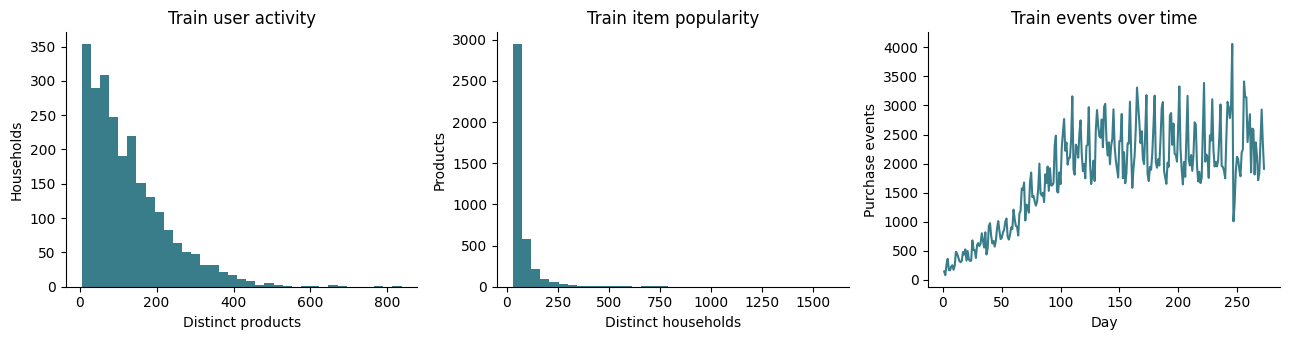

,user_activity,item_popularity
count,2382.000000,4000.000000
mean,125.512594,74.742750
std,102.477486,82.978753
min,5.000000,30.000000
25%,48.250000,38.000000
50%,99.000000,50.000000
75%,176.000000,77.000000
max,837.000000,1598.000000


In [4]:
activity = np.diff(X_train.indptr)
popularity = np.asarray(X_train.sum(axis=0)).ravel()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(activity, bins=35, color='#397d8b')
axes[0].set(xlabel='Distinct products', ylabel='Households', title='Train user activity')
axes[1].hist(popularity, bins=35, color='#397d8b')
axes[1].set(xlabel='Distinct households', ylabel='Products', title='Train item popularity')
train.groupby('DAY').size().plot(ax=axes[2], color='#397d8b')
axes[2].set(xlabel='Day', ylabel='Purchase events', title='Train events over time')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'user_activity': pd.Series(activity).describe(),
                      'item_popularity': pd.Series(popularity).describe()}))

,missing_or_blank
DEPARTMENT,0
COMMODITY_DESC,0
BRAND,0


,field,categories
0,DEPARTMENT,17
1,COMMODITY_DESC,175
2,BRAND,2


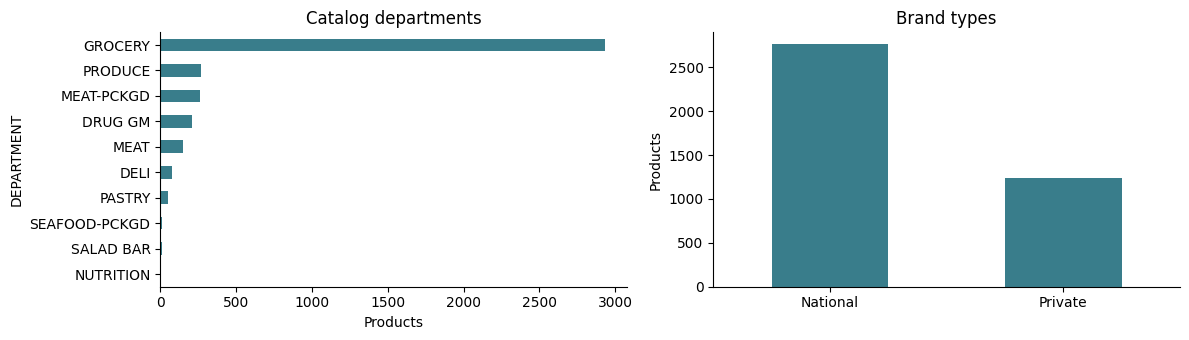

In [5]:
meta_fields = ['DEPARTMENT', 'COMMODITY_DESC', 'BRAND']
missing_metadata = pd.DataFrame({
    'missing_or_blank': [int(metadata[c].fillna('').astype(str).str.strip().eq('').sum()) for c in meta_fields]
}, index=meta_fields)
display(missing_metadata)
display(feature_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
metadata.DEPARTMENT.str.strip().value_counts().head(10).sort_values().plot.barh(ax=axes[0], color='#397d8b')
axes[0].set(title='Catalog departments', xlabel='Products')
metadata.BRAND.str.strip().value_counts().plot.bar(ax=axes[1], rot=0, color='#397d8b')
axes[1].set(title='Brand types', ylabel='Products', xlabel='')
plt.tight_layout()
plt.show()

## 3. Протокол оценки

- **Train:** дни 1–273.
- **Validation:** дни 274–319.
- **Test:** дни 320–365.

Разбиение глобальное: любая обучающая покупка раньше любой покупки периода проверки. Для validation модели обучаются на train. После выбора параметров обучаю их заново на train + validation и оцениваю на test. Каталог, ID пользователей и словари категорий остаются фиксированными.

Проверка идёт по всему выбранному каталогу, без подмешивания случайных негативов. Уже купленные товары исключаются, даже если их покупали повторно. В релевантный набор входят только ранее не купленные товары. Новых пользователей и товары вне обучающего каталога исключаю: здесь оценивается warm-start discovery. Пользователь участвует в метриках, если у него есть хотя бы один доступный новый товар в следующем периоде. Контекст проверки создаётся один раз для всех моделей.

Основную метрику **NDCG@10** выбираю до подбора: она учитывает позиции подходящих товаров. **Recall@10** показывает, какую долю новых покупок удалось найти. Метрики сначала считаются для каждого домохозяйства, затем усредняются. Дополнительно показываю HR@10 и покрытие каталога.

Для релевантного множества $H_u$ и списка $L_u$:

$$Recall@10_u=\frac{|L_u\cap H_u|}{|H_u|},\qquad
NDCG@10_u=\frac{\sum_{r=1}^{10}\mathbf1[L_{u,r}\in H_u]/\log_2(r+1)}
{\sum_{r=1}^{\min(10,|H_u|)}1/\log_2(r+1)}.$$

Равные scores разрешаю по возрастанию `PRODUCT_ID`. Это одинаковое правило для всех методов.

In [6]:
valid_context = evaluation_context(X_train, valid)
display(pd.Series(valid_context['report'], name='validation').to_frame())
coverage_rows = []
for label, left, right, mapped in [('train', 0, TRAIN_DAY, train),
                                 ('validation', TRAIN_DAY, VALID_DAY, valid),
                                 ('test', VALID_DAY, LAST_DAY, test)]:
    raw_period = first_year[(first_year.DAY > left) & (first_year.DAY <= right)]
    coverage_rows.append({'period': label, 'all_clean_events': len(raw_period),
                          'selected_events': len(mapped), 'retained_share': len(mapped) / len(raw_period),
                          'outside_catalog': int((~raw_period.PRODUCT_ID.isin(item_ids)).sum()),
                          'outside_user_set': int((~raw_period.household_key.isin(user_ids)).sum())})
display(pd.DataFrame(coverage_rows))
popularity_valid, _ = evaluate(Popularity().fit(X_train), valid_context)
display(pd.Series(popularity_valid, name='Popularity').to_frame().round(4))

,validation
users,1988
candidate_items,4000
future_distinct_pairs,83496
repeated_pairs,36379
cold_item_pairs,0
relevant_pairs,47117


,period,all_clean_events,selected_events,retained_share,outside_catalog,outside_user_set
0,train,819780,492569,0.600855,327039,8272
1,validation,183613,105581,0.575019,77863,1914
2,test,184185,105098,0.570611,78826,2115


,Popularity
NDCG@10,0.0729
Recall@10,0.0317
HR@10,0.4205
Coverage@10,0.0145
users,1988.0000


## 4. Модели

Все реализации лежат в `models/`. Используются NumPy и SciPy; готовых рекомендательных алгоритмов нет. Вспомогательные функции подготовки и проверки вынесены отдельно, как в семинарах.

### Item-based CF

$X_{ui}=1$, если покупка наблюдалась. Сходство товаров — cosine по столбцам бинарной матрицы с поправкой на число общих покупателей:

$$s_{ij}=\frac{X_i^\top X_j}{\|X_i\|\|X_j\|}\cdot\frac{n_{ij}}{n_{ij}+\beta}.$$

Оставляю до $k$ положительных соседей каждого целевого товара, диагональ обнуляю. Scores: $S=XW$. Центрирование оценок не используется: у покупок нет звёздных оценок.

### iALS

$$\min_{U,V}\sum_{u,i}c_{ui}(p_{ui}-U_u^\top V_i)^2+
\lambda(\|U\|_F^2+\|V\|_F^2),\qquad p_{ui}=X_{ui},\quad c_{ui}=1+\alpha X_{ui}.$$

Поочерёдно решаю нормальные системы для пользователей и товаров. Например,

$$U_u=(V^\top V+\alpha V_{I_u}^\top V_{I_u}+\lambda I)^{-1}
(1+\alpha)V_{I_u}^\top p_{u,I_u}.$$

В коде используется решение системы, а не вычисление обратной матрицы. Пропуски имеют низкую уверенность $c=1$.

### EASE

$$\min_{\operatorname{diag}(B)=0}\|X-XB\|_F^2+\lambda\|B\|_F^2.$$

$$P=(X^\top X+\lambda I)^{-1},\qquad B_{ij}=-P_{ij}/P_{jj}\ (i\ne j),\quad B_{jj}=0.$$

Деление идёт по столбцам. Отрицательные веса сохраняю. Scores: $S=XB$.

### FM

Признаки: one-hot ID пользователя, ID товара, отдела, товарной группы и типа марки. Категории дают общие параметры для разных товаров. Пропуски заменяются на `UNKNOWN`. Использую только свойства самого товара, считая отдел, товарную группу и тип марки фиксированными на рассматриваемом интервале. Это допущение: исторических версий каталога нет. Цены из будущего чека, размер будущей корзины, скидки и маркетинговые отклики не используются.

$$s(x)=\sum_a w_ax_a+\frac12\sum_f\left[\left(\sum_a v_{af}x_a\right)^2-\sum_a v_{af}^2x_a^2\right].$$

Обучение — BPR с L2-регуляризацией:

$$L=\frac1{|D|}\sum_{(u,i,j)\in D}\log(1+e^{-(s(u,i)-s(u,j))})+
\frac\lambda2(\|w\|^2+\|V\|_F^2).$$

Одна эпоха проходит все разные обучающие пары. Негатив равномерно выбирается из известных товаров, которые пользователь не покупал в текущей истории. Будущие покупки не используются при выборе негативов. Градиенты и Adam реализованы вручную. Общий bias в BPR сокращается и зафиксирован в нуле.

### iALS с частотой и давностью

Вместо бинарного предпочтения предлагаю сигнал

$$p^{custom}_{ui}=\begin{cases}
(1-e^{-n_{ui}/s})\,e^{-(T-t^{last}_{ui})/\tau}, & n_{ui}>0,\\
0, & n_{ui}=0.
\end{cases}$$

$n_{ui}$ — число разных чеков с товаром, $t^{last}_{ui}$ — день последней покупки, $T$ — последний день доступной истории. Повторные покупки усиливают сигнал с насыщением, а давние ослабляют. Не использую количество физических единиц: оно несопоставимо для весовых и штучных товаров. Заранее фиксирую $s=2$, $\tau=90$ дней.

Меняется **целевое значение $p$ в ошибке восстановления**. Confidence остаётся таким же, как в базовом iALS: $c_{ui}=1+\alpha X_{ui}$. Поэтому это не настройка confidence. Нормальные системы те же, меняется их правая часть. Сигнал может оказаться неудачным для новых товаров: повторные покупки не входят в критерий качества, это проверит эксперимент.

In [7]:
check_implementations()

X_fit, counts_fit, days_fit = X_train, counts_train, days_train
cutoff_fit = TRAIN_DAY

def fit_model(name, setting, use_metadata=True):
    if name == 'ItemKNN':
        return ItemKNN(**setting).fit(X_fit)
    if name == 'EASE':
        return EASE(**setting).fit(X_fit)
    if name == 'iALS':
        return IALS(**setting, seed=SEED).fit(X_fit)
    if name == 'Custom iALS':
        return CustomIALS(**setting, seed=SEED).fit(X_fit, counts_fit, days_fit, cutoff_fit)
    if name == 'FM':
        features = item_features if use_metadata else id_features
        return FM(**setting, seed=SEED).fit(X_fit, features)
    raise ValueError(name)

Проверки EASE, iALS, FM и метрик пройдены.


## 5. Подбор параметров на validation

Для всех пяти моделей выбираю максимум NDCG@10 на одних и тех же пользователях и кандидатах. При равенстве оставляю первую конфигурацию в сетке. Test не участвует в выборе.

Сетки небольшие: это сравнение нескольких настроек, а не полный поиск оптимума. Число итераций iALS фиксировано в 8; число факторов и регуляризация подбираются. У FM число эпох также входит в поиск. У кастомного iALS та же сетка факторов и регуляризации, что у обычного, чтобы не давать ему преимущество за счёт более широкого поиска.

Это ограниченный поиск. У EASE лучший вариант оказался на верхней границе регуляризации, у ItemKNN — числа соседей, у FM — числа эпох. Значения за этими границами не проверялись. У обоих iALS фиксированы `alpha=20` и восемь итераций, поэтому поиск не устанавливает достаточность числа итераций и лучшую настройку confidence. Параметры кастомного таргета также фиксированы. Выводы ниже относятся к этим конфигурациям; глобальный оптимум параметров не установлен.

In [8]:
als_grid = [{'factors': f, 'reg': r, 'alpha': 20.0, 'iterations': 8}
            for f in [32, 64] for r in [1.0, 10.0]]
fm_grid = [{'factors': 16, 'epochs': e, 'lr': 0.005, 'reg': r, 'batch_size': 1024}
           for e, r in [(8, 1e-5), (16, 1e-5), (16, 1e-4)]]
grids = {
    'ItemKNN': [{'neighbors': k, 'shrink': s} for k in [30, 100] for s in [10.0, 100.0]],
    'iALS': als_grid,
    'EASE': [{'reg': r} for r in [10.0, 100.0, 500.0]],
    'FM': fm_grid,
    'Custom iALS': [dict(setting, tau=90.0, frequency_scale=2.0) for setting in als_grid],
}
display(pd.DataFrame([{'model': name, 'search_space': str(grid)} for name, grid in grids.items()]))

,model,search_space
0,ItemKNN,"[{'neighbors': 30, 'shrink': 10.0}, {'neighbors': 30, 'shrink': 100.0}, {'neighbors': 100, 'shrink': 10.0}, {'neighbors': 100, 'shrink':..."
1,iALS,"[{'factors': 32, 'reg': 1.0, 'alpha': 20.0, 'iterations': 8}, {'factors': 32, 'reg': 10.0, 'alpha': 20.0, 'iterations': 8}, {'factors': ..."
2,EASE,"[{'reg': 10.0}, {'reg': 100.0}, {'reg': 500.0}]"
3,FM,"[{'factors': 16, 'epochs': 8, 'lr': 0.005, 'reg': 1e-05, 'batch_size': 1024}, {'factors': 16, 'epochs': 16, 'lr': 0.005, 'reg': 1e-05, '..."
4,Custom iALS,"[{'factors': 32, 'reg': 1.0, 'alpha': 20.0, 'iterations': 8, 'tau': 90.0, 'frequency_scale': 2.0}, {'factors': 32, 'reg': 10.0, 'alpha':..."


In [9]:
search_rows, selected = [], {}
for name, grid in grids.items():
    values = []
    for setting in grid:
        started = perf_counter()
        model = fit_model(name, setting)
        fit_seconds = perf_counter() - started
        metrics, _ = evaluate(model, valid_context)
        row = {'model': name, 'parameters': json.dumps(setting, sort_keys=True),
               'fit_seconds': fit_seconds, **metrics}
        search_rows.append(row)
        values.append(metrics[PRIMARY_METRIC])
        print(name, setting, 'NDCG@10 =', round(metrics[PRIMARY_METRIC], 5), flush=True)
        del model
        gc.collect()
    selected[name] = dict(grid[int(np.argmax(values))])
search = pd.DataFrame(search_rows)
display(search.round(4))
print('Выбрано по validation:')
display(pd.Series({name: str(params) for name, params in selected.items()}).to_frame('parameters'))

ItemKNN {'neighbors': 30, 'shrink': 10.0} NDCG@10 = 0.08007
ItemKNN {'neighbors': 30, 'shrink': 100.0} NDCG@10 = 0.07913
ItemKNN {'neighbors': 100, 'shrink': 10.0} NDCG@10 = 0.08325
ItemKNN {'neighbors': 100, 'shrink': 100.0} NDCG@10 = 0.08128
iALS {'factors': 32, 'reg': 1.0, 'alpha': 20.0, 'iterations': 8} NDCG@10 = 0.04741
iALS {'factors': 32, 'reg': 10.0, 'alpha': 20.0, 'iterations': 8} NDCG@10 = 0.04954
iALS {'factors': 64, 'reg': 1.0, 'alpha': 20.0, 'iterations': 8} NDCG@10 = 0.04321
iALS {'factors': 64, 'reg': 10.0, 'alpha': 20.0, 'iterations': 8} NDCG@10 = 0.04488
EASE {'reg': 10.0} NDCG@10 = 0.06119
EASE {'reg': 100.0} NDCG@10 = 0.07873
EASE {'reg': 500.0} NDCG@10 = 0.08794
FM {'factors': 16, 'epochs': 8, 'lr': 0.005, 'reg': 1e-05, 'batch_size': 1024} NDCG@10 = 0.07556
FM {'factors': 16, 'epochs': 16, 'lr': 0.005, 'reg': 1e-05, 'batch_size': 1024} NDCG@10 = 0.07759
FM {'factors': 16, 'epochs': 16, 'lr': 0.005, 'reg': 0.0001, 'batch_size': 1024} NDCG@10 = 0.07359
Custom iALS {'f

,model,parameters,fit_seconds,NDCG@10,Recall@10,HR@10,Coverage@10,users
0,ItemKNN,"{""neighbors"": 30, ""shrink"": 10.0}",3.2514,0.0801,0.0357,0.4658,0.1420,1988
1,ItemKNN,"{""neighbors"": 30, ""shrink"": 100.0}",2.7449,0.0791,0.0331,0.4507,0.0815,1988
2,ItemKNN,"{""neighbors"": 100, ""shrink"": 10.0}",3.0624,0.0832,0.0362,0.4688,0.0870,1988
3,ItemKNN,"{""neighbors"": 100, ""shrink"": 100.0}",3.0665,0.0813,0.0350,0.4608,0.0482,1988
4,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8, ""reg"": 1.0}",9.9493,0.0474,0.0259,0.3325,0.5262,1988
5,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8, ""reg"": 10.0}",6.7478,0.0495,0.0267,0.3486,0.5022,1988
6,iALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 8, ""reg"": 1.0}",15.7604,0.0432,0.0223,0.3099,0.5292,1988
7,iALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 8, ""reg"": 10.0}",16.0091,0.0449,0.0236,0.3194,0.5125,1988
8,EASE,"{""reg"": 10.0}",6.2109,0.0612,0.0264,0.3773,0.2500,1988
9,EASE,"{""reg"": 100.0}",5.5515,0.0787,0.0358,0.4718,0.1892,1988


,parameters
ItemKNN,"{'neighbors': 100, 'shrink': 10.0}"
iALS,"{'factors': 32, 'reg': 10.0, 'alpha': 20.0, 'iterations': 8}"
EASE,{'reg': 500.0}
FM,"{'factors': 16, 'epochs': 16, 'lr': 0.005, 'reg': 1e-05, 'batch_size': 1024}"
Custom iALS,"{'factors': 64, 'reg': 10.0, 'alpha': 20.0, 'iterations': 8, 'tau': 90.0, 'frequency_scale': 2.0}"


### Отдельная проверка метаданных FM

Повторяю ту же сетку FM без дополнительных признаков. Сохраняются seed, выбор негативов, BPR и правило полных эпох. Показываю и лучшие варианты каждого представления, и сравнение при одинаковых настройках основной FM. Это помогает отличить эффект признаков от эффекта параметров.

In [10]:
ids_rows = []
for setting in fm_grid:
    model = fit_model('FM', setting, use_metadata=False)
    metrics, _ = evaluate(model, valid_context)
    ids_rows.append({'parameters': json.dumps(setting, sort_keys=True), **metrics})
    print('FM IDs', setting, 'NDCG@10 =', round(metrics[PRIMARY_METRIC], 5), flush=True)
    del model
fm_ids_search = pd.DataFrame(ids_rows)
selected_ids = dict(fm_grid[int(fm_ids_search[PRIMARY_METRIC].to_numpy().argmax())])
display(fm_ids_search.round(4))

selected_json = json.dumps(selected['FM'], sort_keys=True)
matched_ids_valid = fm_ids_search[fm_ids_search.parameters == selected_json].iloc[0]
meta_valid = search[(search.model == 'FM') & (search.parameters == selected_json)].iloc[0]
display(pd.DataFrame([{'features': 'IDs', PRIMARY_METRIC: matched_ids_valid[PRIMARY_METRIC]},
                      {'features': 'IDs + metadata', PRIMARY_METRIC: meta_valid[PRIMARY_METRIC]}]))

FM IDs {'factors': 16, 'epochs': 8, 'lr': 0.005, 'reg': 1e-05, 'batch_size': 1024} NDCG@10 = 0.07956
FM IDs {'factors': 16, 'epochs': 16, 'lr': 0.005, 'reg': 1e-05, 'batch_size': 1024} NDCG@10 = 0.08441
FM IDs {'factors': 16, 'epochs': 16, 'lr': 0.005, 'reg': 0.0001, 'batch_size': 1024} NDCG@10 = 0.07268


,parameters,NDCG@10,Recall@10,HR@10,Coverage@10,users
0,"{""batch_size"": 1024, ""epochs"": 8, ""factors"": 16, ""lr"": 0.005, ""reg"": 1e-05}",0.0796,0.0352,0.4527,0.0853,1988
1,"{""batch_size"": 1024, ""epochs"": 16, ""factors"": 16, ""lr"": 0.005, ""reg"": 1e-05}",0.0844,0.0372,0.4769,0.1140,1988
2,"{""batch_size"": 1024, ""epochs"": 16, ""factors"": 16, ""lr"": 0.005, ""reg"": 0.0001}",0.0727,0.0313,0.4235,0.0145,1988


,features,NDCG@10
0,IDs,0.084409
1,IDs + metadata,0.077587


### Проверка кастомного сигнала при одинаковых настройках

Основная таблица сравнит лучшие варианты по validation. Дополнительно оставляю факторы, регуляризацию, confidence и число итераций как у выбранного базового iALS и меняю только таргет. Настройку такого сравнения фиксирую до test.

In [11]:
matched_custom = dict(selected['iALS'], tau=90.0, frequency_scale=2.0)
base_json = json.dumps(selected['iALS'], sort_keys=True)
custom_json = json.dumps(matched_custom, sort_keys=True)
base_valid = search[(search.model == 'iALS') & (search.parameters == base_json)].iloc[0]
custom_valid = search[(search.model == 'Custom iALS') & (search.parameters == custom_json)].iloc[0]
display(pd.DataFrame([{'target': 'binary', PRIMARY_METRIC: base_valid[PRIMARY_METRIC]},
                      {'target': 'frequency + recency', PRIMARY_METRIC: custom_valid[PRIMARY_METRIC]}]))

frozen_settings = json.dumps({'main': selected, 'fm_ids': selected_ids,
                             'custom_matched': matched_custom}, sort_keys=True)
print('Параметры зафиксированы. Далее — итоговая проверка на test.')

Параметры зафиксированы. Далее — итоговая проверка на test.


,target,NDCG@10
0,binary,0.049540
1,frequency + recency,0.057295


## 6. Итоговое сравнение на test

Переобучаю модели с выбранными настройками на днях 1–319. Для кастомного сигнала пересчитываю частоты и давность на новой доступной истории, $T=319$. Общая релевантность остаётся бинарной покупкой нового товара в днях 320–365. После этого настройки не меняются.

In [12]:
full_history = pd.concat([train, valid], ignore_index=True)
X_fit, counts_fit, days_fit = history_matrices(full_history, shape)
cutoff_fit = VALID_DAY
test_context = evaluation_context(X_fit, test)
display(pd.Series(test_context['report'], name='test').to_frame())
final_rows, final_details, fitted = [], {}, {}

pop_model = Popularity().fit(X_fit)
metrics, details = evaluate(pop_model, test_context)
final_rows.append({'model': 'Popularity', 'parameters': '{}', 'fit_seconds': 0.0, **metrics})
final_details['Popularity'] = details
for name, setting in selected.items():
    started = perf_counter()
    model = fit_model(name, setting)
    fit_seconds = perf_counter() - started
    metrics, details = evaluate(model, test_context)
    fitted[name] = model
    final_details[name] = details
    final_rows.append({'model': name, 'parameters': json.dumps(setting, sort_keys=True),
                       'fit_seconds': fit_seconds, **metrics})
    print(name, 'test NDCG@10 =', round(metrics[PRIMARY_METRIC], 5), flush=True)
results = pd.DataFrame(final_rows).sort_values(PRIMARY_METRIC, ascending=False).reset_index(drop=True)
assert json.dumps({'main': selected, 'fm_ids': selected_ids, 'custom_matched': matched_custom}, sort_keys=True) == frozen_settings
display(results.round(4))

ItemKNN test NDCG@10 = 0.07968
iALS test NDCG@10 = 0.04616
EASE test NDCG@10 = 0.08911
FM test NDCG@10 = 0.07472
Custom iALS test NDCG@10 = 0.05034


,test
users,1968
candidate_items,4000
future_distinct_pairs,81901
repeated_pairs,39117
cold_item_pairs,0
relevant_pairs,42784


,model,parameters,fit_seconds,NDCG@10,Recall@10,HR@10,Coverage@10,users
0,EASE,"{""reg"": 500.0}",6.3483,0.0891,0.0470,0.4898,0.1128,1968
1,ItemKNN,"{""neighbors"": 100, ""shrink"": 10.0}",4.9106,0.0797,0.0399,0.4543,0.0765,1968
2,FM,"{""batch_size"": 1024, ""epochs"": 16, ""factors"": 16, ""lr"": 0.005, ""reg"": 1e-05}",49.3751,0.0747,0.0368,0.4284,0.1045,1968
3,Popularity,{},0.0000,0.0679,0.0329,0.3948,0.0155,1968
4,Custom iALS,"{""alpha"": 20.0, ""factors"": 64, ""frequency_scale"": 2.0, ""iterations"": 8, ""reg"": 10.0, ""tau"": 90.0}",14.8612,0.0503,0.0259,0.3262,0.2050,1968
5,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8, ""reg"": 10.0}",7.9176,0.0462,0.0283,0.3100,0.5545,1968


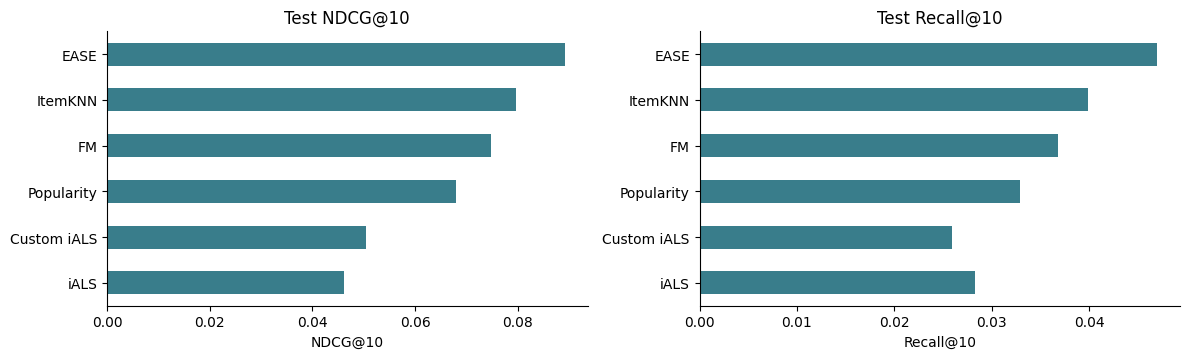

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    results.plot.barh(x='model', y=metric, ax=ax, legend=False, color='#397d8b')
    ax.invert_yaxis()
    ax.set(xlabel=metric, ylabel='', title='Test ' + metric)
plt.tight_layout()
plt.show()

In [14]:
ids_model = fit_model('FM', selected_ids, use_metadata=False)
ids_metrics, ids_details = evaluate(ids_model, test_context)
if selected_ids == selected['FM']:
    ids_matched_metrics, ids_matched_details = ids_metrics, ids_details
else:
    ids_matched = fit_model('FM', selected['FM'], use_metadata=False)
    ids_matched_metrics, ids_matched_details = evaluate(ids_matched, test_context)
    del ids_matched
if matched_custom == selected['Custom iALS']:
    custom_matched_metrics = results[results.model == 'Custom iALS'].iloc[0].to_dict()
    custom_matched_details = final_details['Custom iALS']
else:
    matched_model = fit_model('Custom iALS', matched_custom)
    custom_matched_metrics, custom_matched_details = evaluate(matched_model, test_context)
    del matched_model

fm_main_metrics = results[results.model == 'FM'].iloc[0]
base_metrics = results[results.model == 'iALS'].iloc[0]
ablation = pd.DataFrame([
    {'comparison': 'FM: IDs, own validation choice', **ids_metrics},
    {'comparison': 'FM: IDs, same settings as metadata', **ids_matched_metrics},
    {'comparison': 'FM: IDs + metadata', **{m: fm_main_metrics[m] for m in ['NDCG@10', 'Recall@10']}},
    {'comparison': 'iALS: binary', **{m: base_metrics[m] for m in ['NDCG@10', 'Recall@10']}},
    {'comparison': 'iALS: custom, same settings as binary', **custom_matched_metrics},
])
ablation = ablation[['comparison', 'NDCG@10', 'Recall@10']]
display(ablation.round(4))

,comparison,NDCG@10,Recall@10
0,"FM: IDs, own validation choice",0.0827,0.0433
1,"FM: IDs, same settings as metadata",0.0827,0.0433
2,FM: IDs + metadata,0.0747,0.0368
3,iALS: binary,0.0462,0.0283
4,"iALS: custom, same settings as binary",0.0501,0.0259


### Неопределённость сравнения

Для двух заранее заданных сравнений считаю парный bootstrap разности NDCG@10 по домохозяйствам. В каждой паре сохраняются одни пользователи. Интервал описывает вариацию по пользователям этого test, но не заменяет проверку на другом периоде и нескольких seed обучения.

In [15]:
def paired_interval(first, second, seed=SEED, repeats=2000):
    merged = first[['u', PRIMARY_METRIC]].merge(second[['u', PRIMARY_METRIC]], on='u', validate='one_to_one')
    assert len(merged) == len(first) == len(second)
    difference = merged[PRIMARY_METRIC + '_x'].to_numpy() - merged[PRIMARY_METRIC + '_y'].to_numpy()
    rng = np.random.default_rng(seed)
    samples = np.array([rng.choice(difference, len(difference), replace=True).mean() for _ in range(repeats)])
    low, high = np.quantile(samples, [0.025, 0.975])
    return {'delta': difference.mean(), 'CI_low': low, 'CI_high': high}

intervals = pd.DataFrame([
    {'comparison': 'FM metadata minus IDs (same settings)',
     **paired_interval(final_details['FM'], ids_matched_details)},
    {'comparison': 'Custom minus binary iALS (same settings)',
     **paired_interval(custom_matched_details, final_details['iALS'])},
])
display(intervals.round(5))

,comparison,delta,CI_low,CI_high
0,FM metadata minus IDs (same settings),-0.00802,-0.01173,-0.00413
1,Custom minus binary iALS (same settings),0.00391,-0.00065,0.00879


### Пример рекомендаций

Беру первое по ID домохозяйство из общей группы test, без отбора по качеству. Таблица показывает рекомендации и наличие товара в будущем наборе, но один пример не заменяет общую оценку.

In [16]:
example_user = min(test_context['truth'])
seen = X_fit.indices[X_fit.indptr[example_user]:X_fit.indptr[example_user + 1]]
example_rows = []
for name in selected:
    scores = fitted[name].score(np.array([example_user]))[0]
    top = top_items(scores, seen, test_context['candidates'])
    for rank, i in enumerate(top, 1):
        example_rows.append({'model': name, 'rank': rank, 'PRODUCT_ID': item_ids[i],
                             'category': str(metadata.iloc[i].COMMODITY_DESC).strip(),
                             'relevant': i in test_context['truth'][example_user]})
print('household_key:', user_ids[example_user])
display(pd.DataFrame(example_rows))

household_key: 1


,model,rank,PRODUCT_ID,category,relevant
0,ItemKNN,1,981760,EGGS,False
1,ItemKNN,2,826249,BAKED BREAD/BUNS/ROLLS,False
2,ItemKNN,3,904360,VEGETABLES SALAD,False
3,ItemKNN,4,1098066,BAKED BREAD/BUNS/ROLLS,False
4,ItemKNN,5,916122,CHICKEN,False
5,ItemKNN,6,923746,EGGS,False
6,ItemKNN,7,860776,VEGETABLES - ALL OTHERS,False
7,ItemKNN,8,854852,TOMATOES,False
8,ItemKNN,9,1068719,SUGARS/SWEETNERS,False
9,ItemKNN,10,844179,BEEF,False


## 7. Выводы

На test лучший из пяти методов — **EASE** с регуляризацией 500: NDCG@10 = **0.0891**, Recall@10 = **0.0470**. У ближайшего основного конкурента, ItemKNN со 100 соседями и shrink = 10, значения 0.0797 и 0.0399. EASE также обошёл популярность: у неё NDCG@10 = 0.0679. В проверенной сетке более сильная регуляризация EASE давала лучший результат и на validation.

Метаданные в выбранной FM не помогли. При одинаковых настройках FM с ID дала NDCG@10 = 0.0827, а FM с категориями и типом марки — 0.0747. Разность составила −0.0080; парный 95% bootstrap-интервал [−0.0117; −0.0041]. В этом эксперименте добавление этих признаков ухудшило результат. Категории довольно общие, и большая часть каталога относится к одному отделу, но для проверки причины потребовались бы другие признаки и отдельные эксперименты.

Кастомный сигнал iALS при тех же параметрах, что у бинарного iALS, повысил NDCG@10 с 0.0462 до 0.0501, но снизил Recall@10 с 0.0283 до 0.0259. Интервал разности NDCG@10 [−0.0007; 0.0088] включает ноль, поэтому уверенного улучшения по этому сравнению нет. С собственными настройками, выбранными на validation, кастомный iALS получил NDCG@10 = 0.0503 и также уступил популярности. Повторяемость и давность не оказались достаточно полезными для рекомендации именно новых товаров.

По результатам этого сравнения выбираю EASE. Его преимущество в данном эксперименте не означает, что он будет лучше на другом периоде или на полном ассортименте.


Ограничения:

- Проверяется рекомендация новых товаров. Повторные покупки, важные для магазина, исключены по условию об уже известных объектах. Польза сигнала повторяемости для такой задачи не гарантирована.
- В каталоге только 4 000 популярных на train товаров, а у пользователей есть минимальная история. Нельзя переносить метрики на полный ассортимент и новых покупателей.
- Метрики усредняются только по пользователям с хотя бы одной новой релевантной покупкой: 1 988 на validation и 1 968 на test. Это не среднее по всем 2 382 домохозяйствам выборки.
- Покупка относится к домохозяйству, а не обязательно к одному человеку. Отсутствие покупки не является надёжной отрицательной меткой.
- Используется один год данных, одно временное разбиение, один seed обучения и небольшие сетки. Для iALS отдельно не проверена зависимость качества от числа итераций и confidence; лучший найденный результат EASE, ItemKNN и FM находится на одной из границ сетки. Это не доказывает преимущество алгоритма при любой настройке. Bootstrap по пользователям не учитывает все источники неопределённости.
- Категории считаются фиксированными свойствами товара. Исторических версий метаданных нет; динамические признаки из будущих чеков не использовались.
- EASE и ItemKNN здесь строят плотную матрицу товаров при обучении. Такое решение не рассчитано на каталог из миллионов позиций.

Источники методов: материалы семинаров 3–6 курса; [iALS, Hu et al. (2008)](https://doi.org/10.1109/ICDM.2008.22), [EASE, Steck (2019)](https://arxiv.org/abs/1905.03375), [FM, Rendle (2010)](https://doi.org/10.1109/ICDM.2010.127).

In [17]:
output = Path('results')
output.mkdir(exist_ok=True)
search.to_csv(output / 'validation.csv', index=False)
results.to_csv(output / 'test.csv', index=False)
ablation.to_csv(output / 'ablation.csv', index=False)
intervals.to_csv(output / 'intervals.csv', index=False)
(output / 'settings.json').write_text(frozen_settings, encoding='utf-8')
print('Результаты сохранены в results/.')

Результаты сохранены в results/.
